# Derivatives Pricing & Volatility Modeling

## Phase 1: Derivative Pricing Foundations

This notebook develops the computational foundations for derivative pricing,
starting with option payoffs and progressing to binomial pricing,
Black-Scholes pricing, and option Greeks.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.optimize import brentq

In [ ]:
def call_payoff(S_T, K):
    return np.maximum(S_T - K, 0)


def put_payoff(S_T, K):
    return np.maximum(K - S_T, 0)

In [ ]:
K = 100

S_T = np.array([80, 90, 100, 110, 120])

call_payoff(S_T, K)

array([ 0,  0,  0, 10, 20])

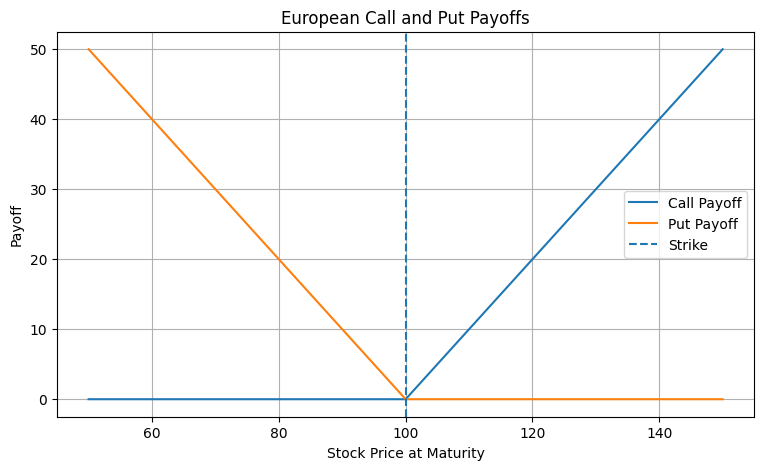

In [ ]:
S_T = np.linspace(50, 150, 500)

call = call_payoff(S_T, K)
put = put_payoff(S_T, K)

plt.figure(figsize=(9, 5))

plt.plot(S_T, call, label="Call Payoff")
plt.plot(S_T, put, label="Put Payoff")

plt.axvline(K, linestyle="--", label="Strike")

plt.xlabel("Stock Price at Maturity")
plt.ylabel("Payoff")
plt.title("European Call and Put Payoffs")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def call_profit(S_T, K, premium):
    return call_payoff(S_T, K) - premium


def put_profit(S_T, K, premium):
    return put_payoff(S_T, K) - premium

In [ ]:
premium = 8

call_profit(120, 100, premium)

np.int64(12)

In [ ]:
call_premium = 8
put_premium = 7

call_break_even = K + call_premium
put_break_even = K - put_premium

call_break_even, put_break_even

(108, 93)

In [ ]:
S0 = 100
K = 100

u = 1.2
d = 0.8

r = 0.05
T = 1

In [ ]:
S_u = S0 * u
S_d = S0 * d

S_u, S_d

(120.0, 80.0)

In [ ]:
C_u = max(S_u - K, 0)
C_d = max(S_d - K, 0)

C_u, C_d

(20.0, 0)

In [ ]:
q = (np.exp(r * T) - d) / (u - d)

q

np.float64(0.6281777409400603)

In [ ]:
C0 = np.exp(-r * T) * (q * C_u + (1 - q) * C_d)

C0

np.float64(11.950823019971445)

## 2. Multi-Step Binomial Model

The stock price at node $(n,j)$ is

$$
S_{n,j}=S_0u^j d^{n-j}
$$

where:

- $n$ = time step
- $j$ = number of upward movements
- $u$ = up factor
- $d$ = down factor

In [ ]:
def stock_price_tree(S0, u, d, N):
    tree = []

    for n in range(N + 1):
        prices = []

        for j in range(n + 1):
            S = S0 * (u ** j) * (d ** (n - j))
            prices.append(S)

        tree.append(prices)

    return tree

In [ ]:
tree = stock_price_tree(100, 1.1, 0.9, 3)

for i, prices in enumerate(tree):
    print(f"Step {i}: {prices}")

Step 0: [100.0]
Step 1: [90.0, 110.00000000000001]
Step 2: [81.0, 99.00000000000001, 121.00000000000001]
Step 3: [72.9, 89.10000000000002, 108.90000000000002, 133.10000000000005]


In [ ]:
S0 = 100
u = 1.1
d = 0.9
N = 3

In [ ]:
K = 100

terminal_prices = tree[-1]

terminal_call_payoffs = [
    max(S - K, 0) for S in terminal_prices
]

terminal_call_payoffs

[0, 0, 8.90000000000002, 33.10000000000005]

In [ ]:
def binomial_european_call(S0, K, r, T, u, d, N):

    dt = T / N

    # Risk-neutral probability
    q = (np.exp(r * dt) - d) / (u - d)

    # Stock prices at maturity
    terminal_prices = [
        S0 * (u ** j) * (d ** (N - j))
        for j in range(N + 1)
    ]

    # Option payoff at maturity
    option_values = [
        max(S - K, 0)
        for S in terminal_prices
    ]

    # Backward induction
    for n in range(N - 1, -1, -1):

        new_values = []

        for j in range(n + 1):

            value = np.exp(-r * dt) * (
                q * option_values[j + 1]
                + (1 - q) * option_values[j]
            )

            new_values.append(value)

        option_values = new_values

    return option_values[0]

In [ ]:
S0 = 100
K = 100
r = 0.05
T = 1
u = 1.1
d = 0.9

for N in [1, 2, 5, 10, 50, 100]:
    price = binomial_european_call(
        S0, K, r, T, u, d, N
    )

    print(N, price)

1 7.194675897467881
2 7.842445902154259
5 11.66307736130043
10 15.002001081201985
50 29.567702021104115
100 39.98489167854092


Cox–Ross–Rubinstein (CRR) Binomial Model

In [ ]:
S0 = 100
K = 100
r = 0.05
sigma = 0.20
T = 1
N = 10

In [ ]:
dt = T / N

u = np.exp(sigma * np.sqrt(dt))
d = np.exp(-sigma * np.sqrt(dt))

dt, u, d

(0.1, np.float64(1.0652883920946086), np.float64(0.9387129414165152))

In [ ]:
q = (np.exp(r * dt) - d) / (u - d)

q

np.float64(0.5237949309104087)

In [ ]:
def crr_european_call(S0, K, r, sigma, T, N):

    dt = T / N

    # CRR up and down factors
    u = np.exp(sigma * np.sqrt(dt))
    d = np.exp(-sigma * np.sqrt(dt))

    # Risk-neutral probability
    q = (np.exp(r * dt) - d) / (u - d)

    # Stock prices at maturity
    terminal_prices = np.array([
        S0 * (u ** j) * (d ** (N - j))
        for j in range(N + 1)
    ])

    # Call payoffs at maturity
    option_values = np.maximum(terminal_prices - K, 0)

    # Backward induction
    for n in range(N - 1, -1, -1):

        option_values = np.exp(-r * dt) * (
            q * option_values[1:n+2]
            + (1 - q) * option_values[0:n+1]
        )

    return option_values[0]

In [ ]:
price = crr_european_call(
    S0=100,
    K=100,
    r=0.05,
    sigma=0.20,
    T=1,
    N=10
)

price

np.float64(10.25340904487193)

In [ ]:
steps = [1, 2, 5, 10, 25, 50, 100, 250, 500]

prices = []

for N in steps:
    price = crr_european_call(
        S0=100,
        K=100,
        r=0.05,
        sigma=0.20,
        T=1,
        N=N
    )

    prices.append(price)

pd.DataFrame({
    "Steps": steps,
    "Binomial Price": prices
})

,Steps,Binomial Price
0,1,12.162285
1,2,9.540501
2,5,10.805934
3,10,10.253409
4,25,10.520966
5,50,10.410692
6,100,10.430612
7,250,10.442589
8,500,10.446585


Calculate Black–Scholes price

In [ ]:
def black_scholes_call(S0, K, r, sigma, T):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call_price = (
        S0 * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    return call_price

In [ ]:
bs_price = black_scholes_call(
    S0=100,
    K=100,
    r=0.05,
    sigma=0.20,
    T=1
)

bs_price

np.float64(10.450583572185565)

In [ ]:
comparison = pd.DataFrame({
    "Steps": steps,
    "Binomial Price": prices
})

comparison["BS Price"] = bs_price
comparison["Absolute Error"] = abs(
    comparison["Binomial Price"] - bs_price
)

comparison

,Steps,Binomial Price,BS Price,Absolute Error
0,1,12.162285,10.450584,1.711701
1,2,9.540501,10.450584,0.910082
2,5,10.805934,10.450584,0.355350
3,10,10.253409,10.450584,0.197175
4,25,10.520966,10.450584,0.070382
5,50,10.410692,10.450584,0.039892
6,100,10.430612,10.450584,0.019972
7,250,10.442589,10.450584,0.007995
8,500,10.446585,10.450584,0.003998


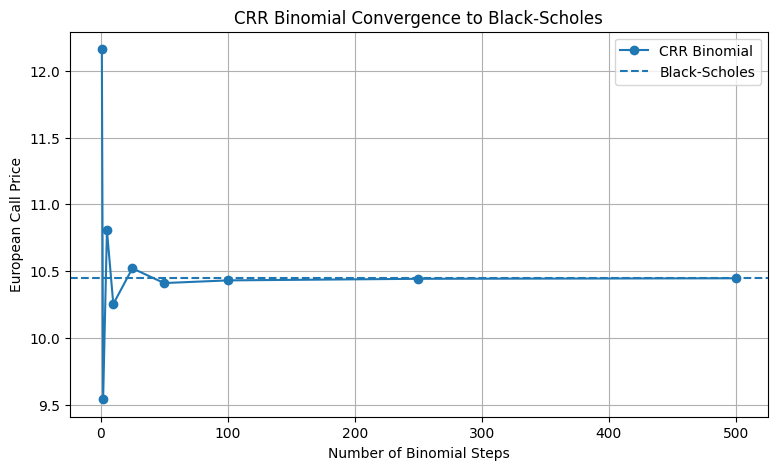

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    prices,
    marker="o",
    label="CRR Binomial"
)

plt.axhline(
    bs_price,
    linestyle="--",
    label="Black-Scholes"
)

plt.xlabel("Number of Binomial Steps")
plt.ylabel("European Call Price")
plt.title("CRR Binomial Convergence to Black-Scholes")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
steps = range(1, 1001)

prices = []

for N in steps:
    price = crr_european_call(
        S0=100,
        K=100,
        r=0.05,
        sigma=0.20,
        T=1,
        N=N
    )

    prices.append(price)

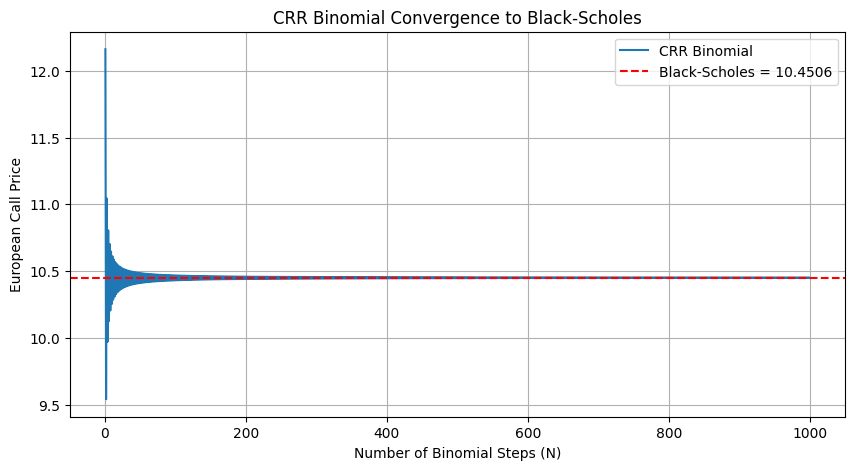

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    prices,
    label="CRR Binomial"
)

plt.axhline(
    bs_price,
    linestyle="--",
    color="r",
    label=f"Black-Scholes = {bs_price:.4f}"
)

plt.xlabel("Number of Binomial Steps (N)")
plt.ylabel("European Call Price")
plt.title("CRR Binomial Convergence to Black-Scholes")
plt.legend()
plt.grid(True)

plt.show()

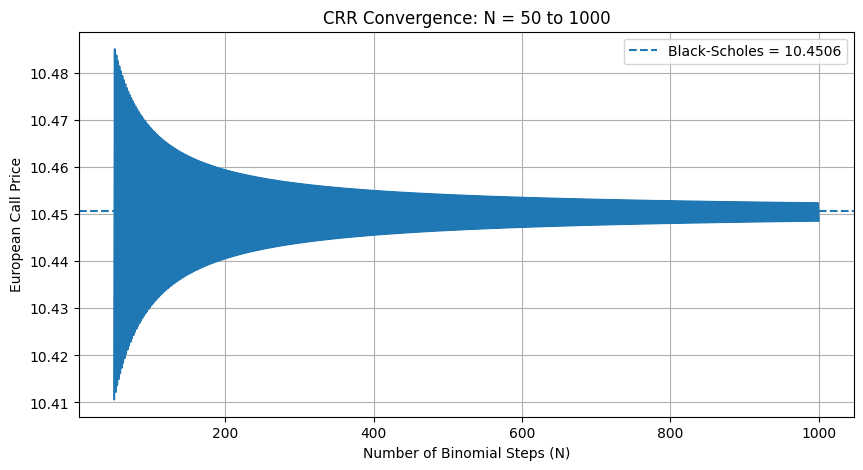

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    list(steps)[49:],
    prices[49:]
)

plt.axhline(
    bs_price,
    linestyle="--",
    label=f"Black-Scholes = {bs_price:.4f}"
)

plt.xlabel("Number of Binomial Steps (N)")
plt.ylabel("European Call Price")
plt.title("CRR Convergence: N = 50 to 1000")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def black_scholes_price(S0, K, r, sigma, T, option_type="call"):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    if option_type == "call":
        price = (
            S0 * norm.cdf(d1)
            - K * np.exp(-r * T) * norm.cdf(d2)
        )

    elif option_type == "put":
        price = (
            K * np.exp(-r * T) * norm.cdf(-d2)
            - S0 * norm.cdf(-d1)
        )

    else:
        raise ValueError("option_type must be 'call' or 'put'")

    return price

In [ ]:
S0 = 100
K = 100
r = 0.05
sigma = 0.20
T = 1

call_price = black_scholes_price(
    S0, K, r, sigma, T, "call"
)

put_price = black_scholes_price(
    S0, K, r, sigma, T, "put"
)

print("Call price:", call_price)
print("Put price:", put_price)

Call price: 10.450583572185565
Put price: 5.573526022256971


In [ ]:
lhs = call_price - put_price
rhs = S0 - K * np.exp(-r * T)

print("C - P =", lhs)
print("S0 - K*exp(-rT) =", rhs)
print("Difference =", lhs - rhs)

C - P = 4.877057549928594
S0 - K*exp(-rT) = 4.877057549928594
Difference = 0.0


In [ ]:
volatilities = np.linspace(0.05, 0.80, 100)

prices = [
    black_scholes_price(
        S0=100,
        K=100,
        r=0.05,
        sigma=sigma,
        T=1,
        option_type="call"
    )
    for sigma in volatilities
]

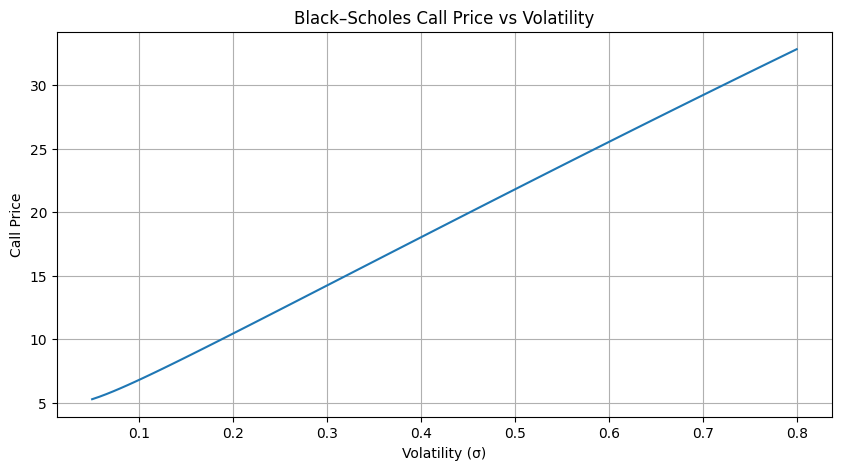

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(volatilities, prices)

plt.xlabel("Volatility (σ)")
plt.ylabel("Call Price")
plt.title("Black–Scholes Call Price vs Volatility")
plt.grid(True)

plt.show()

Implied Volatility Method

In [ ]:
def implied_volatility(
    market_price,
    S0,
    K,
    r,
    T,
    option_type="call"
):

    def objective(sigma):
        model_price = black_scholes_price(
            S0=S0,
            K=K,
            r=r,
            sigma=sigma,
            T=T,
            option_type=option_type
        )

        return model_price - market_price

    try:
        return brentq(objective, 1e-6, 5.0)
    except ValueError:
        return np.nan

In [ ]:
S0 = 100
K = 100
r = 0.05
T = 1
true_sigma = 0.20

market_price = black_scholes_price(
    S0,
    K,
    r,
    true_sigma,
    T,
    "call"
)

print("Option price:", market_price)

Option price: 10.450583572185565


In [ ]:
estimated_sigma = implied_volatility(
    market_price=market_price,
    S0=S0,
    K=K,
    r=r,
    T=T,
    option_type="call"
)

print("Implied volatility:", estimated_sigma)

Implied volatility: 0.20000000000000007


In [ ]:
sigma_grid = np.linspace(0.01, 0.80, 200)

bs_prices = [
    black_scholes_price(
        S0=100,
        K=100,
        r=0.05,
        sigma=sigma,
        T=1,
        option_type="call"
    )
    for sigma in sigma_grid
]

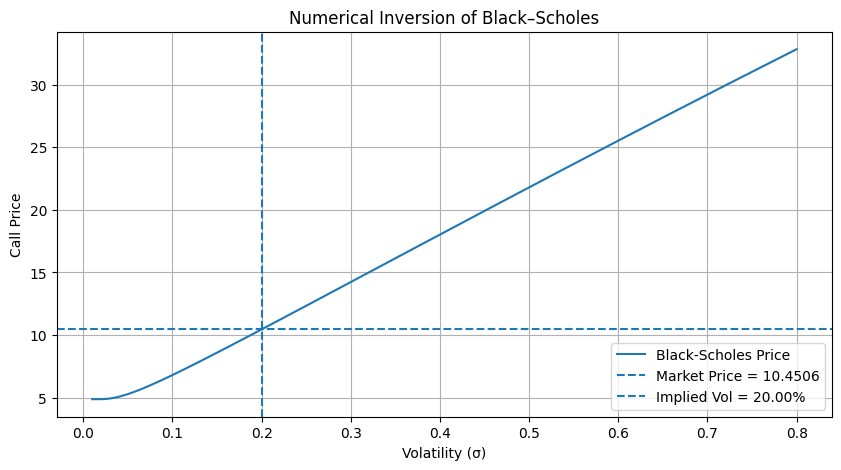

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    sigma_grid,
    bs_prices,
    label="Black-Scholes Price"
)

plt.axhline(
    market_price,
    linestyle="--",
    label=f"Market Price = {market_price:.4f}"
)

plt.axvline(
    estimated_sigma,
    linestyle="--",
    label=f"Implied Vol = {estimated_sigma:.2%}"
)

plt.xlabel("Volatility (σ)")
plt.ylabel("Call Price")
plt.title("Numerical Inversion of Black–Scholes")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
market_prices = [8, 10, 12, 15, 20]

for price in market_prices:
    iv = implied_volatility(
        market_price=price,
        S0=100,
        K=100,
        r=0.05,
        T=1,
        option_type="call"
    )

    print(
        f"Price = {price:5.2f} "
        f"→ IV = {iv:.2%}"
    )

Price =  8.00 → IV = 13.38%
Price = 10.00 → IV = 18.80%
Price = 12.00 → IV = 24.11%
Price = 15.00 → IV = 32.03%
Price = 20.00 → IV = 45.23%


In [ ]:
true_volatilities = np.array([
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40
])

In [ ]:
schole_prices = [
    black_scholes_price(
        S0=100,
        K=100,
        r=0.05,
        sigma=sigma,
        T=1,
        option_type="call"
    )
    for sigma in true_volatilities
]

In [ ]:
recovered_volatilities = [
    implied_volatility(
        market_price=price,
        S0=100,
        K=100,
        r=0.05,
        T=1,
        option_type="call"
    )
    for price in schole_prices
]

In [ ]:
iv_test = pd.DataFrame({
    "True Volatility": true_volatilities,
    "Option Price": schole_prices,
    "Recovered IV": recovered_volatilities
})

iv_test

,True Volatility,Option Price,Recovered IV
0,0.10,6.804958,0.10
1,0.15,8.591658,0.15
2,0.20,10.450584,0.20
3,0.25,12.335999,0.25
4,0.30,14.231255,0.30
5,0.40,18.022951,0.40


Greeks - Delta

In [ ]:
def bs_delta(S0, K, r, sigma, T, option_type="call"):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    if option_type == "call":
        return norm.cdf(d1)

    elif option_type == "put":
        return norm.cdf(d1) - 1

In [ ]:
delta_call = bs_delta(100, 100, 0.05, 0.20, 1, "call")
delta_put = bs_delta(100, 100, 0.05, 0.20, 1, "put")

print("Call Delta:", delta_call)
print("Put Delta:", delta_put)

Call Delta: 0.6368306511756191
Put Delta: -0.3631693488243809


Gamma

In [ ]:
def bs_gamma(S0, K, r, sigma, T):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    return (
        norm.pdf(d1)
        / (S0 * sigma * np.sqrt(T))
    )

def bs_vega(S0, K, r, sigma, T):

    d1 = (
        np.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    return S0 * norm.pdf(d1) * np.sqrt(T)



In [ ]:
gamma = bs_gamma(100, 100, 0.05, 0.20, 1)

print("Gamma:", gamma)

Gamma: 0.018762017345846895


In [ ]:
stock_prices = np.linspace(50, 150, 200)

deltas = [
    bs_delta(
        S0=S,
        K=100,
        r=0.05,
        sigma=0.20,
        T=1,
        option_type="call"
    )
    for S in stock_prices
]

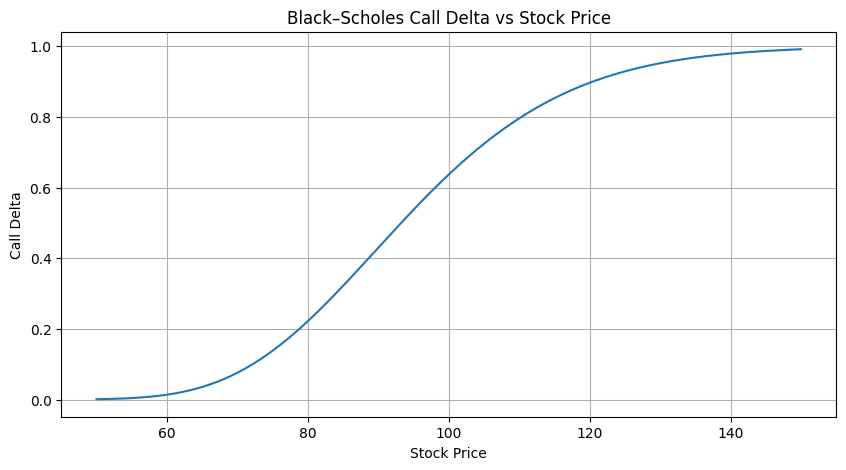

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(stock_prices, deltas)

plt.xlabel("Stock Price")
plt.ylabel("Call Delta")
plt.title("Black–Scholes Call Delta vs Stock Price")
plt.grid(True)

plt.show()

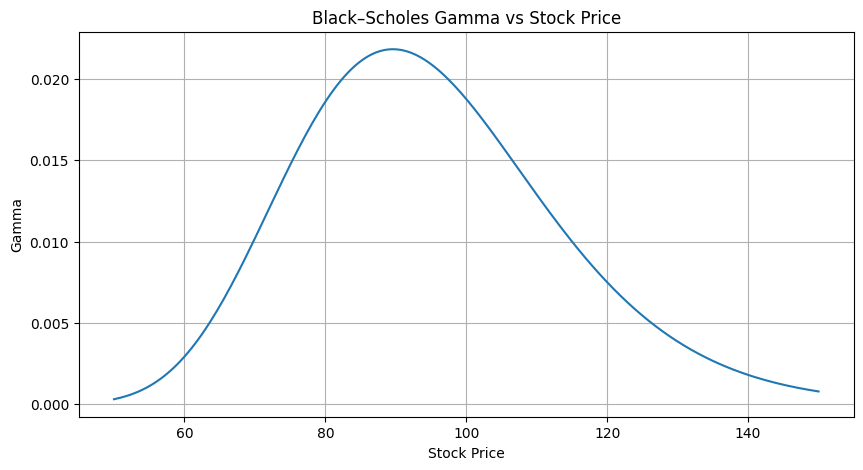

In [ ]:
gammas = [
    bs_gamma(
        S0=S,
        K=100,
        r=0.05,
        sigma=0.20,
        T=1
    )
    for S in stock_prices
]

plt.figure(figsize=(10, 5))

plt.plot(stock_prices, gammas)

plt.xlabel("Stock Price")
plt.ylabel("Gamma")
plt.title("Black–Scholes Gamma vs Stock Price")
plt.grid(True)

plt.show()

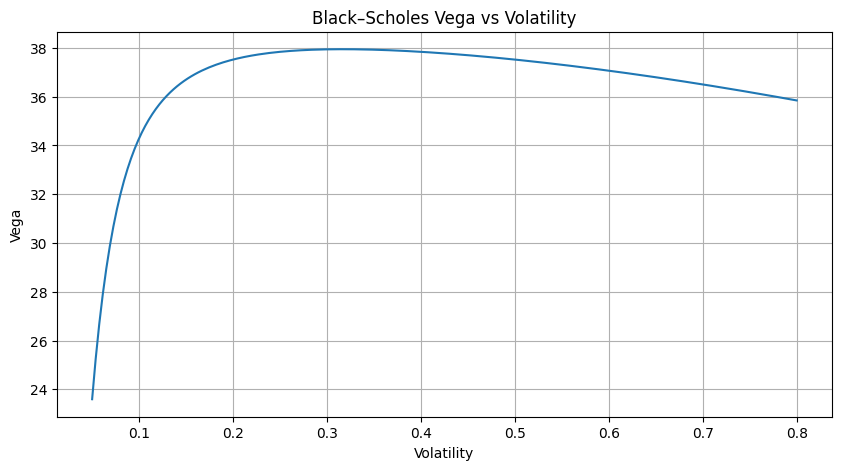

In [ ]:
volatility_grid = np.linspace(0.05, 0.80, 200)

vegas = [
    bs_vega(
        S0=100,
        K=100,
        r=0.05,
        sigma=sigma,
        T=1
    )
    for sigma in volatility_grid
]

plt.figure(figsize=(10, 5))

plt.plot(volatility_grid, vegas)

plt.xlabel("Volatility")
plt.ylabel("Vega")
plt.title("Black–Scholes Vega vs Volatility")
plt.grid(True)

plt.show()

Black Scholes further

In [ ]:
strikes = np.arange(70, 131, 5)

S0 = 100
r = 0.05
sigma = 0.20
T = 1

In [ ]:
option_prices = [
    black_scholes_price(
        S0=S0,
        K=K,
        r=r,
        sigma=sigma,
        T=T,
        option_type="call"
    )
    for K in strikes
]

In [ ]:
option_chain = pd.DataFrame({
    "Strike": strikes,
    "Call Price": option_prices
})

option_chain

,Strike,Call Price
0,70,33.540098
1,75,28.974371
2,80,24.588835
3,85,20.469288
4,90,16.699448
5,95,13.346465
6,100,10.450584
7,105,8.021352
8,110,6.040088
9,115,4.466579


In [ ]:
option_chain_data = []

for K, price in zip(strikes, option_prices):

    iv = implied_volatility(
        market_price=price,
        S0=S0,
        K=K,
        r=r,
        T=T,
        option_type="call"
    )

    option_chain_data.append({
        "Strike": K,
        "Call Price": price,
        "Implied Volatility": iv
    })

option_chain = pd.DataFrame(option_chain_data)

option_chain

,Strike,Call Price,Implied Volatility
0,70,33.540098,0.2
1,75,28.974371,0.2
2,80,24.588835,0.2
3,85,20.469288,0.2
4,90,16.699448,0.2
5,95,13.346465,0.2
6,100,10.450584,0.2
7,105,8.021352,0.2
8,110,6.040088,0.2
9,115,4.466579,0.2


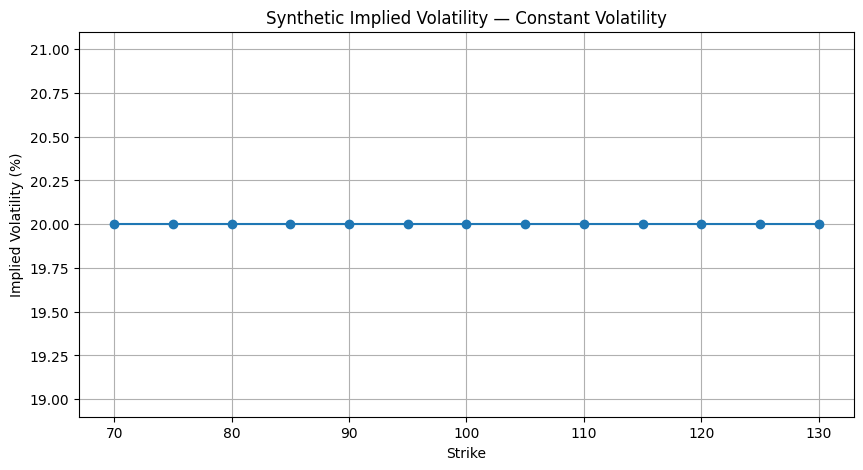

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    option_chain["Strike"],
    option_chain["Implied Volatility"].round(6) * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title("Synthetic Implied Volatility — Constant Volatility")
plt.grid(True)

plt.show()

In [ ]:
synthetic_vols = (
    0.20
    + 0.00008 * (strikes - 100)**2
)

synthetic_vols

array([0.272, 0.25 , 0.232, 0.218, 0.208, 0.202, 0.2  , 0.202, 0.208,
       0.218, 0.232, 0.25 , 0.272])

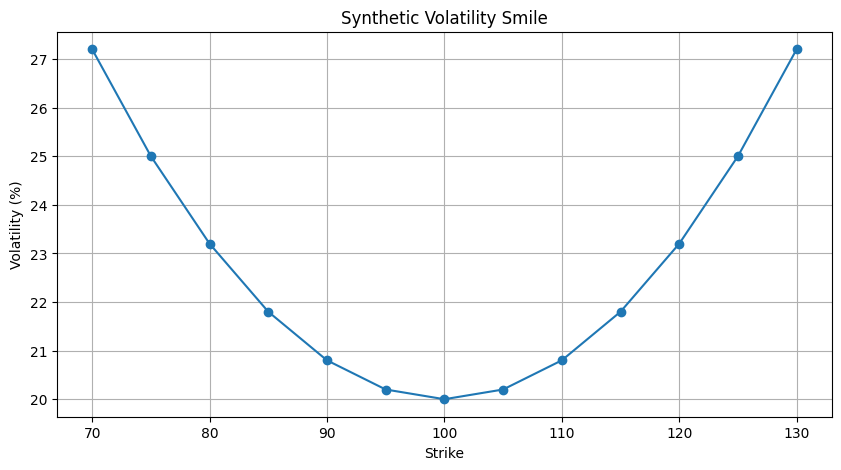

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    strikes,
    synthetic_vols * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Volatility (%)")
plt.title("Synthetic Volatility Smile")
plt.grid(True)

plt.show()

In [ ]:
smile_prices = [
    black_scholes_price(
        S0=S0,
        K=K,
        r=r,
        sigma=sigma,
        T=T,
        option_type="call"
    )
    for K, sigma in zip(strikes, synthetic_vols)
]

In [ ]:
smile_chain = pd.DataFrame({
    "Strike": strikes,
    "Market Price": smile_prices
})

smile_chain

,Strike,Market Price
0,70,34.067292
1,75,29.515328
2,80,25.085506
3,85,20.851994
4,90,16.919245
5,95,13.412931
6,100,10.450584
7,105,8.100689
8,110,6.356945
9,115,5.147626


In [ ]:
smile_chain["Implied Volatility"] = [
    implied_volatility(
        market_price=price,
        S0=S0,
        K=K,
        r=r,
        T=T,
        option_type="call"
    )
    for K, price in zip(
        smile_chain["Strike"],
        smile_chain["Market Price"]
    )
]

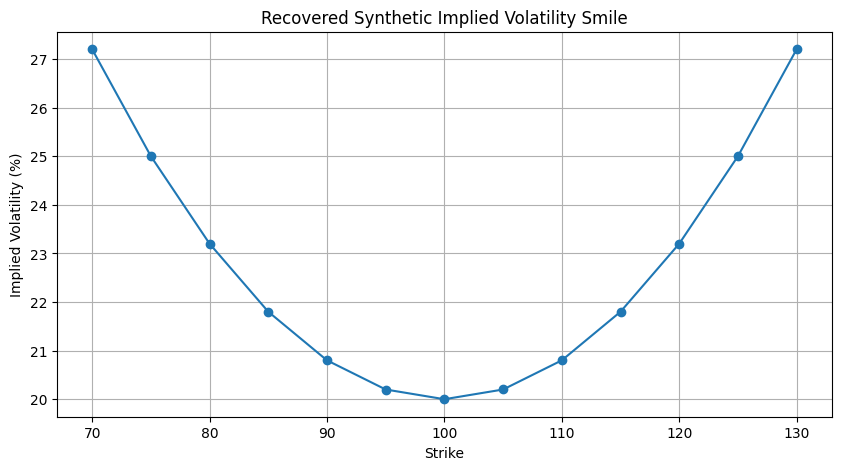

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    smile_chain["Strike"],
    smile_chain["Implied Volatility"] * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Implied Volatility (%)")
plt.title("Recovered Synthetic Implied Volatility Smile")
plt.grid(True)

plt.show()

In [ ]:
smile_chain["True Volatility"] = synthetic_vols

smile_chain["IV Error"] = (
    smile_chain["Implied Volatility"]
    - smile_chain["True Volatility"]
)

print(smile_chain)
print(
    "Maximum absolute IV error:",
    smile_chain["IV Error"].abs().max()
)

    Strike  Market Price  Implied Volatility  True Volatility      IV Error
0       70     34.067292               0.272            0.272  7.771561e-16
1       75     29.515328               0.250            0.250  2.415290e-13
2       80     25.085506               0.232            0.232  1.297573e-13
3       85     20.851994               0.218            0.218 -1.276756e-15
4       90     16.919245               0.208            0.208  5.273559e-16
5       95     13.412931               0.202            0.202 -2.643996e-13
6      100     10.450584               0.200            0.200  5.551115e-17
7      105      8.100689               0.202            0.202  1.665335e-16
8      110      6.356945               0.208            0.208 -1.942890e-16
9      115      5.147626               0.218            0.218 -2.775558e-17
10     120      4.370449               0.232            0.232 -1.387779e-16
11     125      3.926904               0.250            0.250  1.665335e-16
12     130  

In [ ]:
synthetic_vols_skew = (
    0.20
    + 0.00008 * (strikes - 100)**2
    - 0.0015 * (strikes - 100)
)

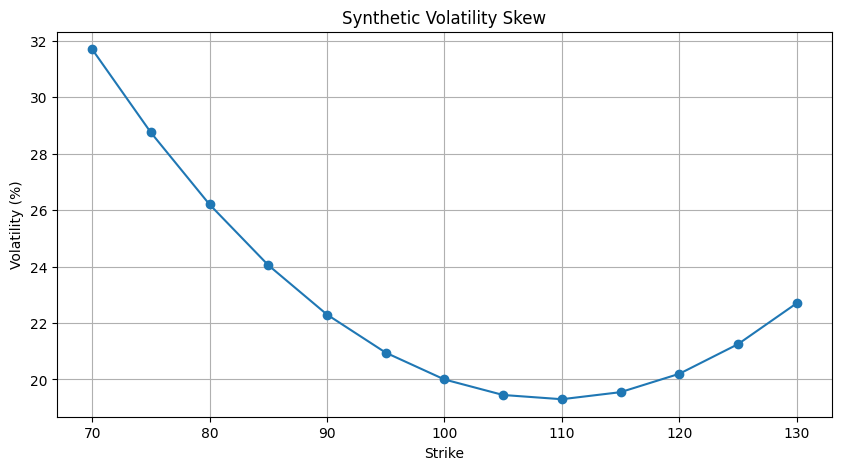

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    strikes,
    synthetic_vols_skew * 100,
    marker="o"
)

plt.xlabel("Strike")
plt.ylabel("Volatility (%)")
plt.title("Synthetic Volatility Skew")
plt.grid(True)

plt.show()

In [ ]:
strikes = np.arange(70, 131, 5)

maturities = np.array([0.10, 0.25, 0.50, 1.00, 2.00])

print("Strikes:", strikes)
print("Maturities:", maturities)

Strikes: [ 70  75  80  85  90  95 100 105 110 115 120 125 130]
Maturities: [0.1  0.25 0.5  1.   2.  ]


In [ ]:
def synthetic_surface_volatility(K, T):
    return (
        0.20
        + 0.00008 * (K - 100)**2
        + 0.01 / np.sqrt(T)
        - 0.01
    )

In [ ]:
vol_surface = np.zeros((len(maturities), len(strikes)))

for i, T in enumerate(maturities):
    for j, K in enumerate(strikes):
        vol_surface[i, j] = synthetic_surface_volatility(K, T)

In [ ]:
pd.DataFrame(
    vol_surface,
    index=maturities,
    columns=strikes
)

,70,75,80,85,90,95,100,105,110,115,120,125,130
0.10,0.293623,0.271623,0.253623,0.239623,0.229623,0.223623,0.221623,0.223623,0.229623,0.239623,0.253623,0.271623,0.293623
0.25,0.282000,0.260000,0.242000,0.228000,0.218000,0.212000,0.210000,0.212000,0.218000,0.228000,0.242000,0.260000,0.282000
0.50,0.276142,0.254142,0.236142,0.222142,0.212142,0.206142,0.204142,0.206142,0.212142,0.222142,0.236142,0.254142,0.276142
1.00,0.272000,0.250000,0.232000,0.218000,0.208000,0.202000,0.200000,0.202000,0.208000,0.218000,0.232000,0.250000,0.272000
2.00,0.269071,0.247071,0.229071,0.215071,0.205071,0.199071,0.197071,0.199071,0.205071,0.215071,0.229071,0.247071,0.269071


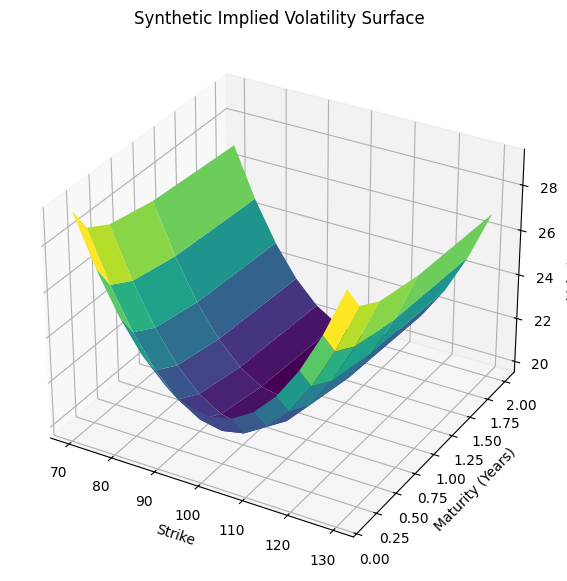

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

K_grid, T_grid = np.meshgrid(strikes, maturities)

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    K_grid,
    T_grid,
    vol_surface * 100,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("Strike")
ax.set_ylabel("Maturity (Years)")
ax.set_zlabel("Volatility (%)")
ax.set_title("Synthetic Implied Volatility Surface")

plt.show()

In [ ]:
surface_prices = np.zeros((len(maturities), len(strikes)))

for i, T in enumerate(maturities):
    for j, K in enumerate(strikes):

        sigma = vol_surface[i, j]

        surface_prices[i, j] = black_scholes_price(
            S0=S0,
            K=K,
            r=r,
            sigma=sigma,
            T=T,
            option_type="call"
        )

pd.DataFrame(
    surface_prices,
    index=maturities,
    columns=strikes
)

,70,75,80,85,90,95,100,105,110,115,120,125,130
0.10,30.349214,25.374688,20.403683,15.456951,10.641230,6.305738,3.044842,1.181084,0.389189,0.122077,0.041490,0.016954,0.008825
0.25,30.885710,25.971485,21.098628,16.337883,11.848920,7.905475,4.811498,2.706666,1.464017,0.806225,0.478689,0.319437,0.244132
0.50,31.882276,27.105809,22.420240,17.909619,13.712965,10.017192,7.002082,4.754184,3.221396,2.252118,1.674584,1.350991,1.190665
1.00,34.067292,29.515328,25.085506,20.851994,16.919245,13.412931,10.450584,8.100689,6.356945,5.147626,4.370449,3.926904,3.740602
2.00,38.339399,34.056097,29.901245,25.933812,22.231004,18.883448,15.980699,13.589863,11.737940,10.408882,9.556376,9.123052,9.056009


In [ ]:
recovered_iv_surface = np.zeros(
    (len(maturities), len(strikes))
)

for i, T in enumerate(maturities):
    for j, K in enumerate(strikes):

        price = surface_prices[i, j]

        recovered_iv_surface[i, j] = implied_volatility(
            market_price=price,
            S0=S0,
            K=K,
            r=r,
            T=T,
            option_type="call"
        )

surface_error = (
    recovered_iv_surface - vol_surface
)

print("Maximum absolute error:",
      np.max(np.abs(surface_error)))

Maximum absolute error: 1.4523937608146298e-12


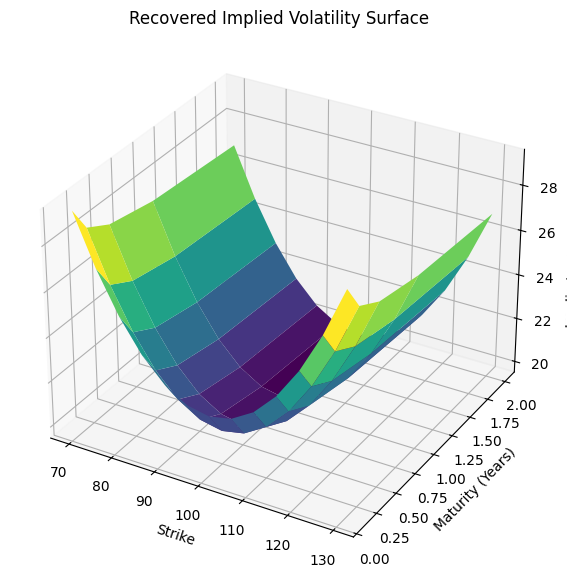

In [ ]:
K_grid, T_grid = np.meshgrid(strikes, maturities)

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    K_grid,
    T_grid,
    recovered_iv_surface * 100,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("Strike")
ax.set_ylabel("Maturity (Years)")
ax.set_zlabel("Implied Volatility (%)")
ax.set_title("Recovered Implied Volatility Surface")

plt.show()

Real-market phase

Observed SPX option price→Black–Scholes inversion→Market IV